# Baltimore 311 Resolution Time: Tree Models (Part 3)

**Team Chingu:** Manikrishneshwar Sasidhar, Yeo Eun Yoon

Part 2 fit a linear regression on 2024 and scored it on 2025. Its conclusion was that almost all of
the fit is the request-type indicators, and that the model lands close to simply predicting each
request type's median. Two things it could not do were use the predictors whose relationship with
resolution time is not additive, and use location, which it left out because neighborhood explains
little of the log-time variation *in a straight additive sense*.

This notebook fits the two tree models that can do both:

1. **Random forest** — many deep trees on bootstrap samples, averaged.
2. **Gradient boosting** (XGBoost) — shallow trees fit in sequence on the running residual.

Both are run on two feature sets: the exact set part 2 used, and an expanded set that adds agency,
intake method, neighborhood, council district and coordinates. Comparing those two answers a
question part 2 had to leave open: **does location matter once a model can use it non-additively?**

Everything else is held identical to part 2 — same rows, same 2024/2025 split, same `log1p` target,
same metrics — so the numbers drop straight into one comparison table.

## 0. Setup

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import statsmodels.api as sm
import xgboost as xgb
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "figures"
RESULTS_DIR = ROOT / "results"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Held identical to part 2.
SLA_MAX = 120
MIN_TYPE_N = 200
SEED = 311

# New in this notebook: the last quarter of 2024 is the validation set.
VALID_START_MONTH = 10
RF_TUNE_N = 150_000

MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def metrics(days_true, log_true, log_pred):
    # Part 2's metrics: MAE/RMSE/R2 in days (via expm1), plus R2 on the log scale.
    days_true = np.asarray(days_true, dtype=float)
    log_true = np.asarray(log_true, dtype=float)
    days_pred = np.expm1(log_pred)
    e_days = days_true - days_pred
    e_log = log_true - log_pred
    return {
        "MAE": np.mean(np.abs(e_days)),
        "RMSE": np.sqrt(np.mean(e_days ** 2)),
        "R2": 1 - (e_days ** 2).sum() / ((days_true - days_true.mean()) ** 2).sum(),
        "R2_log": 1 - (e_log ** 2).sum() / ((log_true - log_true.mean()) ** 2).sum(),
    }

/Users/yun-yeoeun/Library/Python/3.11/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load the cleaned data and reproduce part 2's rows

The raw Open Baltimore files hold 1,081,868 requests for 2024 and 931,323 for 2025, **2,013,191 in
all**. The cleaning notebook reduces that to 931,339 — it drops 311 call-centre information
requests, city-generated proactive work, and anything still open (no close date, so no target).
More than half the raw file is therefore gone before any modelling, which is worth stating plainly
in the write-up because the deck quotes the raw totals.

Same file and same deadline filter as part 2: `sla_days` from 0 through 120 days. The asserts are
there so this notebook fails loudly if the cleaning output ever changes underneath it.

In [2]:
df = pd.read_parquet(PROCESSED_DIR / "311_clean_2024_2025.parquet")
n_clean = len(df)
df = df[df["sla_days"].between(0, SLA_MAX)].copy()

# Request types rarer than MIN_TYPE_N in the 2024 training year collapse into "Other",
# exactly as in part 2. The vocabulary comes from the training year only.
is_2024 = df["source_year"] == 2024
type_counts = df.loc[is_2024, "SRType"].value_counts()
common_types = set(type_counts[type_counts >= MIN_TYPE_N].index)
df["request_type"] = np.where(df["SRType"].isin(common_types), df["SRType"].astype(str), "Other")

print(f"Cleaned file          {n_clean:>10,} rows")
print(f"Deadline 0-{SLA_MAX} days     {len(df):>10,} rows")
print(f"  2024 (train)        {is_2024.sum():>10,}")
print(f"  2025 (test)         {(~is_2024).sum():>10,}")
print(f"Request types with their own level: {len(common_types)}")
print(f"Share in Other: 2024 {(df.loc[is_2024, 'request_type'] == 'Other').mean():.1%}   "
      f"2025 {(df.loc[~is_2024, 'request_type'] == 'Other').mean():.1%}")

assert len(df) == 923_522, len(df)
assert is_2024.sum() == 489_223
assert len(common_types) == 138
print("\nMatches part 2.")

Cleaned file             931,339 rows
Deadline 0-120 days        923,522 rows
  2024 (train)           489,223
  2025 (test)            434,299
Request types with their own level: 138
Share in Other: 2024 1.4%   2025 1.9%

Matches part 2.


## 2. Train, validation, test

Part 2 fit on 2024 and scored 2025 once. That is the right outer split, and it stays. But tree
models have hyperparameters to choose, and choosing them on the test year would quietly turn 2025
into training data.

So 2024 is split again, by time: **January–September 2024 tunes, October–December 2024 validates.**
The split is by date rather than at random because part 2 found that errors cluster in time — whole
months of 2025 were slower than the 2024 fit predicted. A random validation split would scatter
each month across both sides and report a rosier number than the model will see on a future year.

Once the hyperparameters are chosen, each model is refit on **all** of 2024 and scored on 2025 once.

In [3]:
df["month_num"] = df["created_month"].astype(int)

train = df[df["source_year"] == 2024]
test = df[df["source_year"] == 2025]
tr_in = train[train["month_num"] < VALID_START_MONTH]
val = train[train["month_num"] >= VALID_START_MONTH]

splits = {"tr_in": tr_in, "val": val, "train": train, "test": test}
y = {k: v["log_resolution_days"].to_numpy() for k, v in splits.items()}
d = {k: v["resolution_days"].to_numpy() for k, v in splits.items()}

print(f"tune       Jan-Sep 2024   {len(tr_in):>10,} rows")
print(f"validate   Oct-Dec 2024   {len(val):>10,} rows")
print(f"train      all 2024       {len(train):>10,} rows")
print(f"test       all 2025       {len(test):>10,} rows")

monthly = pd.crosstab(df["month_num"], df["source_year"])
monthly.index = MONTH_NAMES
monthly.columns = ["2024", "2025"]
print("\nRequests per month after filtering")
display(monthly)

tune       Jan-Sep 2024      383,881 rows
validate   Oct-Dec 2024      105,342 rows
train      all 2024          489,223 rows
test       all 2025          434,299 rows

Requests per month after filtering


,2024,2025
Jan,41433,43276
Feb,37222,36270
Mar,37965,39759
Apr,43544,3085
May,46366,11140
Jun,42981,46829
Jul,45306,49226
Aug,49562,51860
Sep,39502,44008
Oct,40442,42162


Two months of 2025 are unusually thin: **April has 3,085 requests and May has 11,140**, against
roughly 43,000 and 46,000 in the same months of 2024. Part 2 noticed April. It is in fact a
two-month hole in the 2025 export. Those months are kept in the test set so that this notebook
scores on the same rows part 2 did, but any month-by-month reading of 2025 has to treat
April and May as a thin slice rather than a real seasonal effect.

## 3. Two feature sets

Every column here is known the moment the request is filed, so none of them leak the answer. The
cleaning notebook already dropped the columns recorded afterwards (`StatusDate`, `LastActivity`,
`Outcome`).

**Set A — exactly what part 2 used.** `sla_days` (the city's own deadline), request type, month,
weekday, hour.

**Set B — A plus the predictors part 2 left out.** Agency, intake method, neighborhood, council
district, latitude and longitude, and the `has_valid_coords` flag.

Set B is worth naming carefully, because it is **the feature set our own methodology slide
describes**. That slide says the regression predicts resolution time "from request type, agency,
intake method (MethodReceived), the city's deadline (DueDate), and date + location features." Part
2's code fits something narrower: it keeps request type, the deadline and the calendar, and drops
agency, intake method and every location column. So set A is what we implemented and set B is what
we presented, and the comparison below is partly an audit of that gap.

Part 2 excluded most of set B for good reasons that are specific to linear regression: agency is
nearly collinear with request type, and neighborhood explains little variance *as an additive
shift*. Neither objection binds a tree. A tree can use neighborhood inside one request type
without claiming neighborhood has the same effect everywhere, which is what an additive shift
asserts. Whether it actually helps is the empirical question of section 8.

Two deliberate omissions from set B: `is_weekend` and `season` are exact functions of
`created_dayofweek` and `created_month`, which are already present, so they would only split
importance between duplicate columns. `ZipCode` and `PoliceDistrict` are dropped for the same
reason, being coarser copies of the geography already covered by neighborhood and council district.

**Encoding.** Tree models do not need one-hot columns, and with 279 request types and 280
neighborhoods one-hot would be wasteful. XGBoost is given pandas `category` columns with
`enable_categorical=True`, and partitions levels natively at each split. The random forest gets
integer codes. Integer codes
impose an arbitrary order, which is a real limitation: a split can only cut that ordering, so a
forest needs several splits to isolate one level. Deep trees can do it, and this is the standard
trade for high-cardinality categoricals, but it is a reason to expect the forest to use these
columns less efficiently than XGBoost.

In [4]:
CATS_A = ["request_type", "created_month", "created_dayofweek", "created_hour"]
NUMS_A = ["sla_days"]
CATS_B = CATS_A + ["Agency", "MethodReceived", "Neighborhood", "CouncilDistrict"]
NUMS_B = NUMS_A + ["Latitude", "Longitude", "has_valid_coords"]

# Categories are built on the full file so train and test share one encoding.
for c in CATS_B:
    df[c] = df[c].astype(str).astype("category")
df["has_valid_coords"] = df["has_valid_coords"].astype(int)

# Rebuild the views now that dtypes changed.
train = df[df["source_year"] == 2024]
test = df[df["source_year"] == 2025]
tr_in = train[train["month_num"] < VALID_START_MONTH]
val = train[train["month_num"] >= VALID_START_MONTH]
splits = {"tr_in": tr_in, "val": val, "train": train, "test": test}

FEATURE_SETS = {"A": (CATS_A, NUMS_A), "B": (CATS_B, NUMS_B)}


def make_X(frame, fs, encoding):
    # encoding='category' for XGBoost (native handling), 'codes' for the random forest.
    cats, nums = FEATURE_SETS[fs]
    X = frame[cats + nums].copy()
    if encoding == "codes":
        for c in cats:
            X[c] = X[c].cat.codes.astype(np.int32)
    return X


for fs, (cats, nums) in FEATURE_SETS.items():
    print(f"Set {fs}: {len(cats) + len(nums)} columns")
    print(f"  categorical ({len(cats)}): {', '.join(cats)}")
    print(f"  numeric     ({len(nums)}): {', '.join(nums)}")
print("\nLevels per categorical column")
display(pd.Series({c: df[c].nunique() for c in CATS_B}, name="levels").to_frame())
print(f"Latitude/Longitude missing: {df['Latitude'].isna().sum():,} rows "
      f"({df['Latitude'].isna().mean():.1%}) -- kept as NaN, which both models split on natively")

Set A: 5 columns
  categorical (4): request_type, created_month, created_dayofweek, created_hour
  numeric     (1): sla_days
Set B: 12 columns
  categorical (8): request_type, created_month, created_dayofweek, created_hour, Agency, MethodReceived, Neighborhood, CouncilDistrict
  numeric     (4): sla_days, Latitude, Longitude, has_valid_coords

Levels per categorical column


,levels
request_type,139
created_month,12
created_dayofweek,7
created_hour,24
Agency,16
MethodReceived,10
Neighborhood,280
CouncilDistrict,15


Latitude/Longitude missing: 22,637 rows (2.5%) -- kept as NaN, which both models split on natively


## 4. Reference points

Three rows to beat, all refit here rather than copied, so the whole table comes out of one run.

- **One median for every request** — the simplest possible rule.
- **The median of each request type** — part 2's finding was that this is most of the signal.
- **Part 2's linear regression** — the same specification, refit.

The two medians are day-scale rules. To score them with the same function as everything else they
are converted to the log scale with `log1p`, which `metrics` then inverts; this is lossless and
leaves their day-scale MAE, RMSE and R² identical to part 2's table.

In [5]:
rows = []
preds = {}  # (model, features) -> log-scale test predictions, for the error analysis later


def record(model, features, log_pred):
    rows.append({"model": model, "features": features,
                 **metrics(d["test"], y["test"], log_pred)})
    preds[(model, features)] = log_pred
    return rows[-1]


# Baseline 1: one median for all.
global_median = np.median(d["train"])
rows.append({"model": "Median, all requests", "features": "--",
             **metrics(d["test"], y["test"], np.log1p(np.full(len(test), global_median)))})

# Baseline 2: median per request type.
type_median = train.groupby("request_type", observed=True)["resolution_days"].median()
rows.append({"model": "Median per request type", "features": "--",
             **metrics(d["test"], y["test"],
                       np.log1p(test["request_type"].map(type_median).to_numpy()))})

# Baseline 3: part 2's linear regression, refit.
ref_type = train["request_type"].value_counts().idxmax()
ref_hour = int(train["created_hour"].astype(int).mode().iloc[0])


def ols_design(frame, columns=None, drop_cols=None):
    p = frame[["sla_days", "request_type", "created_month",
               "created_dayofweek", "created_hour"]].copy()
    for c in ("created_month", "created_dayofweek", "created_hour"):
        p[c] = p[c].astype(int)
    X = pd.get_dummies(p, columns=["request_type", "created_month",
                                   "created_dayofweek", "created_hour"], dtype=float)
    if columns is None:
        return sm.add_constant(X.drop(columns=drop_cols), has_constant="add")
    return sm.add_constant(X, has_constant="add").reindex(columns=columns, fill_value=0.0)


drop_cols = [f"request_type_{ref_type}", "created_month_1",
             "created_dayofweek_0", f"created_hour_{ref_hour}"]
X_ols_train = ols_design(train, drop_cols=drop_cols)
X_ols_test = ols_design(test, columns=list(X_ols_train.columns))
ols = sm.OLS(y["train"], X_ols_train.to_numpy()).fit()
rows.append({"model": "Linear regression (part 2)", "features": "A",
             **metrics(d["test"], y["test"], ols.predict(X_ols_test.to_numpy()))})

print(f"Reference type {ref_type!r}, reference hour {ref_hour}:00")
print(f"Linear regression: {int(ols.df_model) + 1} coefficients, training R2(log) {ols.rsquared:.4f}")
print("(Part 2 reported 180 coefficients and 0.5441.)\n")
display(pd.DataFrame(rows).round(3))

Reference type 'HCD-Sanitation Property', reference hour 10:00
Linear regression: 180 coefficients, training R2(log) 0.5441
(Part 2 reported 180 coefficients and 0.5441.)



,model,features,MAE,RMSE,R2,R2_log
0,"Median, all requests",--,14.7120,38.8830,-0.1150,-0.0350
1,Median per request type,--,11.9150,35.9590,0.0470,0.2640
2,Linear regression (part 2),A,11.5900,35.8720,0.0510,0.3150


## 5. Random forest

A forest grows many deep trees, each on a bootstrap sample of the rows and a random subset of
columns at every split, then averages them. The averaging is what controls variance: individual
deep trees overfit badly, but their errors are partly independent, so the mean is far steadier than
any one of them.

Three settings matter here and the grid below covers them.

- `max_features` — columns considered per split. Lower means more decorrelated, more varied trees.
- `min_samples_leaf` — the floor on leaf size, which is the main brake on depth. With half a
  million rows a leaf of 1 would memorize individual requests.
- `n_estimators` — more trees only ever helps accuracy, with diminishing returns and linear cost.

Following the project plan, tuning runs on a **150,000-row subsample** of January–September with 200
trees, which keeps the grid to about a minute. The winning setting is then refit on all of 2024 with
300 trees. Subsampling for tuning is safe in a way that subsampling for the final fit is not: it
costs some precision in *ranking* the settings, but the model that gets scored still sees every row.

In [6]:
RF_GRID = [{"max_features": mf, "min_samples_leaf": msl}
           for mf in ["sqrt", 0.5] for msl in [5, 20, 50]]

tune_idx = np.random.default_rng(SEED).choice(len(tr_in), RF_TUNE_N, replace=False)
rf_tuning, rf_best = [], {}

for fs in ("A", "B"):
    X_tune = make_X(tr_in, fs, "codes").iloc[tune_idx]
    y_tune = y["tr_in"][tune_idx]
    X_val = make_X(val, fs, "codes")
    for g in RF_GRID:
        t = time.time()
        m = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=SEED, **g)
        m.fit(X_tune, y_tune)
        rf_tuning.append({"features": fs, **g,
                          "valid_MAE": metrics(d["val"], y["val"], m.predict(X_val))["MAE"],
                          "seconds": time.time() - t})
    best = min([r for r in rf_tuning if r["features"] == fs], key=lambda r: r["valid_MAE"])
    rf_best[fs] = {"max_features": best["max_features"], "min_samples_leaf": best["min_samples_leaf"]}
    print(f"Set {fs} best: {rf_best[fs]}  valid MAE {best['valid_MAE']:.3f}")

print("\nValidation MAE in days, Oct-Dec 2024")
display(pd.DataFrame(rf_tuning).round(3))

Set A best: {'max_features': 'sqrt', 'min_samples_leaf': 5}  valid MAE 8.632


Set B best: {'max_features': 0.5, 'min_samples_leaf': 20}  valid MAE 8.421

Validation MAE in days, Oct-Dec 2024


,features,max_features,min_samples_leaf,valid_MAE,seconds
0,A,sqrt,5,8.6320,1.8000
1,A,sqrt,20,8.6380,1.5110
2,A,sqrt,50,8.7120,1.4310
3,A,0.5000,5,8.6320,1.7600
4,A,0.5000,20,8.6380,1.5260
5,A,0.5000,50,8.7120,1.3680
6,B,sqrt,5,8.5800,3.0740
7,B,sqrt,20,8.6840,2.8460
8,B,sqrt,50,8.8450,2.5000
9,B,0.5000,5,8.4900,5.6000


In [7]:
rf_models, rf_pred = {}, {}
for fs in ("A", "B"):
    t = time.time()
    m = RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=SEED, **rf_best[fs])
    m.fit(make_X(train, fs, "codes"), y["train"])
    rf_models[fs] = m
    rf_pred[fs] = m.predict(make_X(test, fs, "codes"))
    r = record("Random forest", fs, rf_pred[fs])
    print(f"Set {fs}: refit on 489,223 rows and scored 2025 in {time.time() - t:.0f}s "
          f"-> test MAE {r['MAE']:.3f} days")

Set A: refit on 489,223 rows and scored 2025 in 11s -> test MAE 10.843 days


Set B: refit on 489,223 rows and scored 2025 in 32s -> test MAE 10.489 days


## 6. Gradient boosting (XGBoost)

Boosting works the other way around. Each tree is shallow and deliberately weak, and it is fit to
what the current ensemble still gets wrong. Predictions are the running sum, so the fit is built up
in small corrective steps rather than averaged down from overfit trees.

We use **XGBoost**, which is the gradient boosting implementation our methodology slide names. Two
settings make it work on this data:

- `tree_method="hist"` buckets each feature into a histogram before searching for splits, which is
  what makes half a million rows fast.
- `enable_categorical=True` with `max_cat_to_onehot=1` lets XGBoost partition categorical levels
  natively — it sorts levels by their gradient statistics and splits that ordering — instead of
  one-hot expanding 139 request types and 280 neighborhoods into a wall of indicator columns.

The number of trees is a parameter to *stop* rather than to raise: past a point the ensemble starts
fitting noise. `early_stopping_rounds=100` watches validation loss on October–December 2024 and
keeps the round where it bottomed out, so the round count is chosen by the data rather than guessed.

The grid varies the two settings that control how much each tree can learn:

- `max_depth` — the complexity ceiling per tree.
- `min_child_weight` — the floor on how much data a leaf must carry, which matters more than usual
  here because categorical partitioning can otherwise carve out very small groups of neighborhoods.

The learning rate is fixed at 0.05, low enough that early stopping lands on a plateau rather than a
spike.

In [8]:
XGB_GRID = [{"max_depth": md_, "min_child_weight": mcw}
            for md_ in [6, 8, 10, 12] for mcw in [1, 20]]
XGB_BASE = dict(learning_rate=0.05, n_estimators=3000, tree_method="hist",
                enable_categorical=True, max_cat_to_onehot=1,
                random_state=SEED, n_jobs=-1)

xgb_tuning, xgb_best = [], {}
for fs in ("A", "B"):
    X_tune, X_val = make_X(tr_in, fs, "category"), make_X(val, fs, "category")
    for g in XGB_GRID:
        m = xgb.XGBRegressor(**XGB_BASE, early_stopping_rounds=100, **g)
        m.fit(X_tune, y["tr_in"], eval_set=[(X_val, y["val"])], verbose=False)
        xgb_tuning.append({"features": fs, **g, "rounds": int(m.best_iteration) + 1,
                           "valid_MAE": metrics(d["val"], y["val"], m.predict(X_val))["MAE"]})
    best = min([r for r in xgb_tuning if r["features"] == fs], key=lambda r: r["valid_MAE"])
    xgb_best[fs] = {"max_depth": best["max_depth"],
                    "min_child_weight": best["min_child_weight"], "rounds": best["rounds"]}
    print(f"Set {fs} best: max_depth={best['max_depth']}, "
          f"min_child_weight={best['min_child_weight']}, rounds={best['rounds']}  "
          f"valid MAE {best['valid_MAE']:.3f}")

print("\nValidation MAE in days, Oct-Dec 2024")
display(pd.DataFrame(xgb_tuning).round(3))

Set A best: max_depth=6, min_child_weight=20, rounds=222  valid MAE 8.389


Set B best: max_depth=6, min_child_weight=20, rounds=247  valid MAE 8.221

Validation MAE in days, Oct-Dec 2024


,features,max_depth,min_child_weight,rounds,valid_MAE
0,A,6,1,185,8.4320
1,A,6,20,222,8.3890
2,A,8,1,105,8.6530
3,A,8,20,163,8.5930
4,A,10,1,81,8.8090
5,A,10,20,100,8.7270
6,A,12,1,76,8.9730
7,A,12,20,108,8.7580
8,B,6,1,331,8.2310
9,B,6,20,247,8.2210


In [9]:
xgb_models, xgb_pred = {}, {}
for fs in ("A", "B"):
    cfg = dict(xgb_best[fs])
    n_rounds = cfg.pop("rounds")
    m = xgb.XGBRegressor(**{**XGB_BASE, "n_estimators": n_rounds}, **cfg)
    m.fit(make_X(train, fs, "category"), y["train"], verbose=False)
    xgb_models[fs] = m
    xgb_pred[fs] = m.predict(make_X(test, fs, "category"))
    r = record("Gradient boosting", fs, xgb_pred[fs])
    print(f"Set {fs}: {n_rounds} rounds -> test MAE {r['MAE']:.3f} days")

Set A: 222 rounds -> test MAE 10.409 days


Set B: 247 rounds -> test MAE 10.826 days


### 6.1 Optimizing the metric we report

Every model so far minimizes squared error on the log scale, which targets the *mean* log time.
We report MAE, which is minimized by the *median*. Those are not the same target, and the long right
tail is exactly where they part company.

XGBoost can minimize absolute error directly with `objective="reg:absoluteerror"`. It is one line,
it fits the metric the project leads with, and it is worth one row in the table. It gets the same
early stopping on the same validation quarter, so the comparison is fair.

In [10]:
m = xgb.XGBRegressor(**XGB_BASE, early_stopping_rounds=100,
                     objective="reg:absoluteerror",
                     max_depth=xgb_best["B"]["max_depth"],
                     min_child_weight=xgb_best["B"]["min_child_weight"])
m.fit(make_X(tr_in, "B", "category"), y["tr_in"],
      eval_set=[(make_X(val, "B", "category"), y["val"])], verbose=False)
n_rounds = int(m.best_iteration) + 1

f = xgb.XGBRegressor(**{**XGB_BASE, "n_estimators": n_rounds},
                     objective="reg:absoluteerror",
                     max_depth=xgb_best["B"]["max_depth"],
                     min_child_weight=xgb_best["B"]["min_child_weight"])
f.fit(make_X(train, "B", "category"), y["train"], verbose=False)
xgb_models["B_mae"] = f
xgb_pred["B_mae"] = f.predict(make_X(test, "B", "category"))
r = record("Gradient boosting, MAE objective", "B", xgb_pred["B_mae"])
print(f"{n_rounds} rounds -> test MAE {r['MAE']:.3f} days   RMSE {r['RMSE']:.3f}   "
      f"R2_log {r['R2_log']:.3f}")

972 rounds -> test MAE 11.162 days   RMSE 35.452   R2_log 0.298


## 7. Model comparison

2025 test set, scored once


,model,features,MAE,RMSE,R2,R2_log
0,"Median, all requests",--,14.7120,38.8830,-0.1150,-0.0350
1,Median per request type,--,11.9150,35.9590,0.0470,0.2640
2,Linear regression (part 2),A,11.5900,35.8720,0.0510,0.3150
3,Random forest,A,10.8430,34.4190,0.1260,0.3320
4,Random forest,B,10.4890,33.7220,0.1610,0.3600
5,Gradient boosting,A,10.4090,33.9370,0.1510,0.3580
6,Gradient boosting,B,10.8260,34.5980,0.1170,0.3540
7,"Gradient boosting, MAE objective",B,11.1620,35.4520,0.0730,0.2980


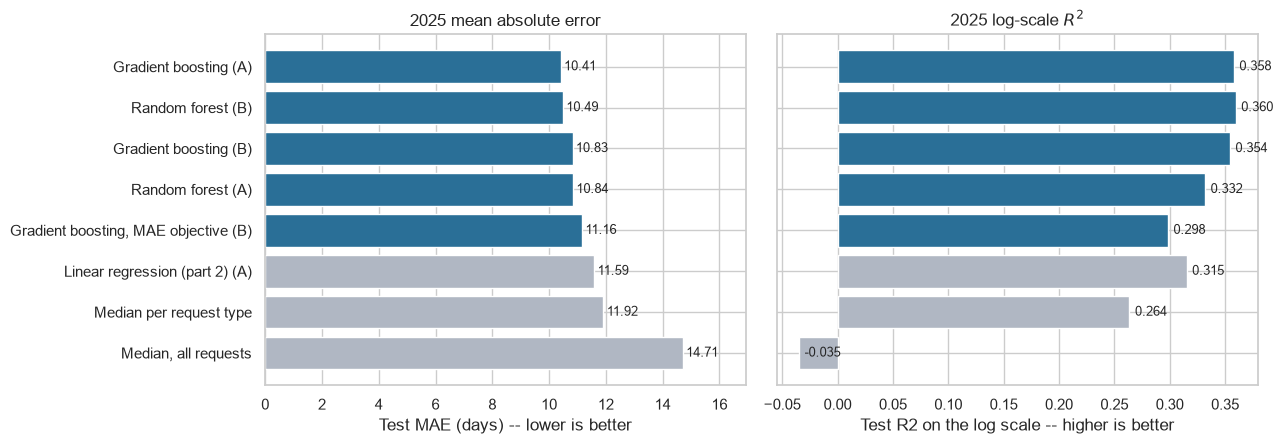

In [11]:
results = pd.DataFrame(rows)
results.to_csv(RESULTS_DIR / "model_comparison.csv", index=False)

print("2025 test set, scored once")
display(results.round(3))

order = results.sort_values("MAE")
labels = [f"{r.model}" + (f" ({r.features})" if r.features != "--" else "")
          for r in order.itertuples()]
colors = ["#b0b7c3" if r.model.startswith(("Median", "Linear")) else "#2a6f97"
          for r in order.itertuples()]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].barh(labels, order["MAE"], color=colors)
axes[0].invert_yaxis()
axes[0].set_xlabel("Test MAE (days) -- lower is better")
axes[0].set_title("2025 mean absolute error")
axes[0].set_xlim(0, max(order["MAE"]) * 1.15)
for i, v in enumerate(order["MAE"]):
    axes[0].text(v + 0.12, i, f"{v:.2f}", va="center", fontsize=9)

axes[1].barh(labels, order["R2_log"], color=colors)
axes[1].invert_yaxis()
axes[1].set_xlabel("Test R2 on the log scale -- higher is better")
axes[1].set_title("2025 log-scale $R^2$")
for i, v in enumerate(order["R2_log"]):
    axes[1].text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=9)
axes[1].set_yticklabels([])
savefig("16_model_comparison")

Four things come out of this table.

**Both tree models beat the linear regression, and the gap is real.** The best model — XGBoost on
set A — cuts test MAE from 11.59 days to **10.41**, about 1.2 days per request, and lifts log-scale
R² from 0.315 to 0.358. That is the first clear improvement over "predict this request type's
median" the project has had: part 2's linear model beat that rule by 0.33 days, while XGBoost beats
it by 1.51. The random forest on set B is close behind at 10.49.

**The expanded feature set moves the two models in opposite directions.** Set B *improves* the
forest (10.84 → 10.49) and *costs* XGBoost (10.41 → 10.83). That is not a small discrepancy: the
same seven columns are worth −0.35 days to one model and +0.42 to the other. Set B adds them all at
once, so this table cannot say which column is responsible, nor whether the result is about the
features themselves or about how each model encodes them. Section 8 adds them one at a time.

**Optimizing MAE directly made things clearly worse** (11.16 against 10.83 for the same features).
That is the opposite of what the reasoning in 6.1 predicted, and it is a genuine negative result
rather than a tuning accident — it got the same early stopping and ran 972 rounds. Section 12
returns to it.

**R² in days stays low for every model.** It never clears 0.17. This is the same long-tail effect
part 2 described: squared error in days is dominated by the minority of requests that take months,
and no model here predicts those. MAE remains the honest headline, and it is still around ten days.

A note on the `R2_log` column for the two median rules. Their day-scale MAE, RMSE and R² match part 2
exactly. Their log-scale R² does not, and should not: part 2's log-scale table scored the *mean log
time* of each request type (0.301), whereas the row here is the *median days* of each type converted
to the log scale (0.264). Both are correct; they are different predictors, and the mean-log version
is the stronger one on a log-scale metric by construction.

## 8. Which of the new features actually did the work?

Set B added seven columns at once, and the forest improved while boosting did not. Adding them one
at a time shows which column carries the gain, and whether the boosting result is a property of the
features or of how XGBoost treats them.

Each boosting variant is tuned by the same early stopping on the same validation quarter, then refit
on 2024 and scored on 2025. The forest reuses one fixed setting throughout, rather than being
retuned per variant: the point here is to isolate the effect of *adding a column*, which a changing
hyperparameter would confound.

In [12]:
VARIANTS = {
    "A (part 2's set)": [],
    "+ Agency": ["Agency"],
    "+ MethodReceived": ["MethodReceived"],
    "+ Latitude/Longitude": ["Latitude", "Longitude", "has_valid_coords"],
    "+ CouncilDistrict": ["CouncilDistrict"],
    "+ Neighborhood": ["Neighborhood"],
    "B (all of the above)": CATS_B[4:] + NUMS_B[1:],
}
base_cols = CATS_A + NUMS_A
inc_rows = []

GB_FIXED = {"max_depth": xgb_best["B"]["max_depth"],
            "min_child_weight": xgb_best["B"]["min_child_weight"]}

for name, extra in VARIANTS.items():
    cols = base_cols + list(extra)
    cats = [c for c in cols if c in CATS_B]

    # XGBoost, early stopped on the validation quarter.
    m = xgb.XGBRegressor(**XGB_BASE, early_stopping_rounds=100, **GB_FIXED)
    m.fit(tr_in[cols], y["tr_in"], eval_set=[(val[cols], y["val"])], verbose=False)
    n_rounds = int(m.best_iteration) + 1
    f = xgb.XGBRegressor(**{**XGB_BASE, "n_estimators": n_rounds}, **GB_FIXED)
    f.fit(train[cols], y["train"], verbose=False)

    # Random forest, with the tuned setting from section 5 and codes for the categoricals.
    def codes(frame):
        X = frame[cols].copy()
        for c in cats:
            X[c] = X[c].cat.codes.astype(np.int32)
        return X

    rf = RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=SEED, **rf_best["B"])
    rf.fit(codes(train), y["train"])

    inc_rows.append({
        "features": name,
        "GB rounds": n_rounds,
        "GB valid MAE": metrics(d["val"], y["val"], m.predict(val[cols]))["MAE"],
        "GB test MAE": metrics(d["test"], y["test"], f.predict(test[cols]))["MAE"],
        "RF test MAE": metrics(d["test"], y["test"], rf.predict(codes(test)))["MAE"],
    })
    print(f"{name:24s} GB valid {inc_rows[-1]['GB valid MAE']:.3f}  "
          f"GB test {inc_rows[-1]['GB test MAE']:.3f}   "
          f"RF test {inc_rows[-1]['RF test MAE']:.3f}", flush=True)

incremental = pd.DataFrame(inc_rows)
incremental.to_csv(RESULTS_DIR / "incremental_features.csv", index=False)
display(incremental.round(3))

A (part 2's set)         GB valid 8.389  GB test 10.409   RF test 10.783


+ Agency                 GB valid 8.394  GB test 10.526   RF test 10.464


+ MethodReceived         GB valid 8.423  GB test 10.390   RF test 10.529


+ Latitude/Longitude     GB valid 8.285  GB test 10.563   RF test 10.623


+ CouncilDistrict        GB valid 8.284  GB test 10.630   RF test 10.646


+ Neighborhood           GB valid 8.276  GB test 11.013   RF test 10.650


B (all of the above)     GB valid 8.221  GB test 10.826   RF test 10.525


,features,GB rounds,GB valid MAE,GB test MAE,RF test MAE
0,A (part 2's set),222,8.3890,10.4090,10.7830
1,+ Agency,221,8.3940,10.5260,10.4640
2,+ MethodReceived,287,8.4230,10.3900,10.5290
3,+ Latitude/Longitude,377,8.2850,10.5630,10.6230
4,+ CouncilDistrict,242,8.2840,10.6300,10.6460
5,+ Neighborhood,198,8.2760,11.0130,10.6500
6,B (all of the above),247,8.2210,10.8260,10.5250


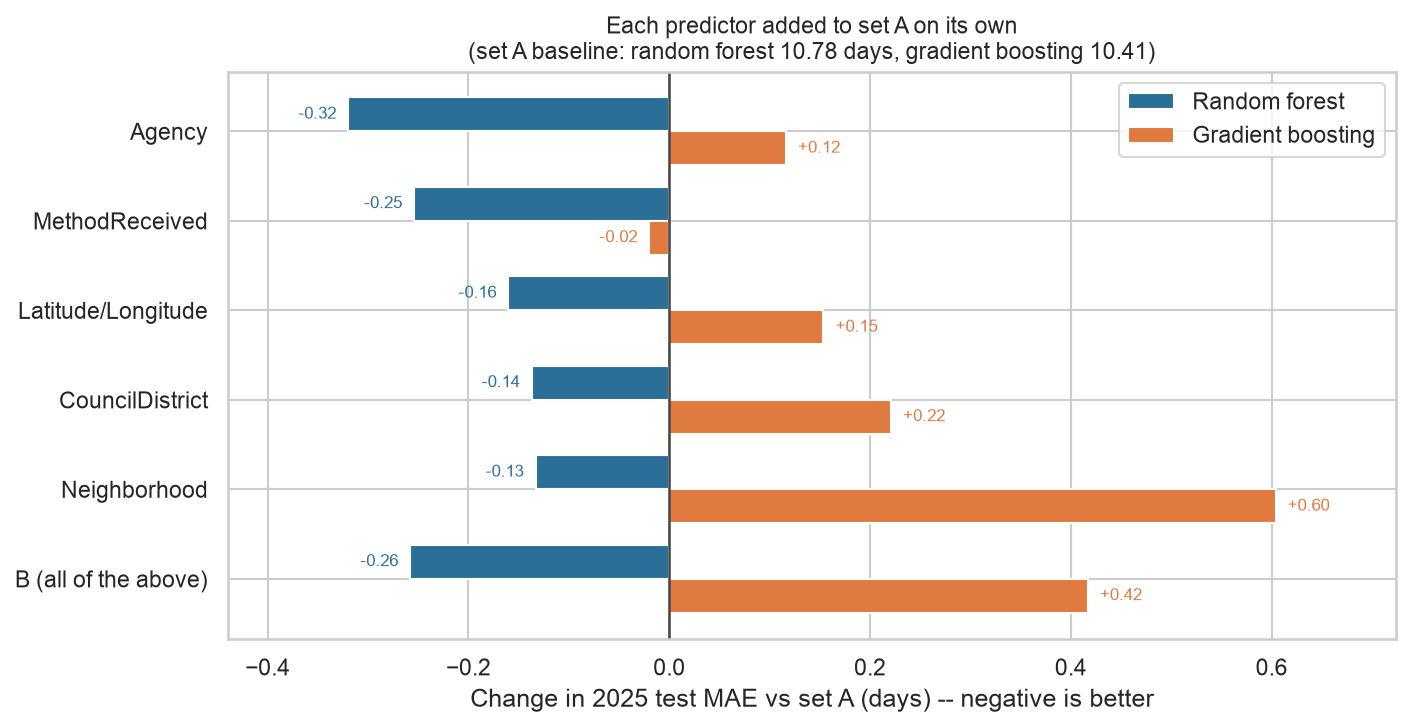

In [13]:
# Each bar is set A plus that one column -- the variants are alternatives, not a running total.
base_rf = incremental.loc[0, "RF test MAE"]
base_gb = incremental.loc[0, "GB test MAE"]
delta = incremental.iloc[1:].copy()
delta["RF"] = delta["RF test MAE"] - base_rf
delta["GB"] = delta["GB test MAE"] - base_gb
delta["label"] = delta["features"].str.replace("^\\+ ", "", regex=True)
delta = delta.iloc[::-1]

fig, ax = plt.subplots(figsize=(9.5, 5))
ypos = np.arange(len(delta))
h = 0.38
ax.barh(ypos + h / 2, delta["RF"], height=h, color="#2a6f97", label="Random forest")
ax.barh(ypos - h / 2, delta["GB"], height=h, color="#e07a3f", label="Gradient boosting")
ax.axvline(0, color="#444", linewidth=1.2)
ax.set_yticks(ypos)
ax.set_yticklabels(delta["label"])
ax.set_xlabel("Change in 2025 test MAE vs set A (days) -- negative is better")
ax.set_title("Each predictor added to set A on its own\n"
             f"(set A baseline: random forest {base_rf:.2f} days, gradient boosting {base_gb:.2f})",
             fontsize=11)
ax.legend(loc="upper right")
for yy, v in zip(ypos + h / 2, delta["RF"]):
    ax.text(v + (0.012 if v >= 0 else -0.012), yy, f"{v:+.2f}",
            va="center", ha="left" if v >= 0 else "right", fontsize=8, color="#2a6f97")
for yy, v in zip(ypos - h / 2, delta["GB"]):
    ax.text(v + (0.012 if v >= 0 else -0.012), yy, f"{v:+.2f}",
            va="center", ha="left" if v >= 0 else "right", fontsize=8, color="#e07a3f")
ax.set_xlim(min(delta[["RF", "GB"]].min()) - 0.12, max(delta[["RF", "GB"]].max()) + 0.12)
savefig("17_incremental_features")

**Almost every column that helps the forest hurts XGBoost.** That is the headline, and it is very
clean:

| Added to set A | Random forest | XGBoost |
|---|---|---|
| Agency | **−0.32** | **+0.12** |
| MethodReceived | −0.25 | −0.02 |
| Latitude/Longitude | −0.16 | +0.15 |
| CouncilDistrict | −0.14 | +0.22 |
| Neighborhood | −0.13 | **+0.60** |
| all of them (set B) | −0.26 | +0.42 |

**Agency is the forest's single best addition and XGBoost's second worst.** For the forest it is
worth more on its own (10.46) than all seven columns together (10.53). For XGBoost it costs 0.12.

**One mechanism explains both columns of that table: how each model reads a categorical.** The
forest sees request type only as arbitrary integer codes, which a split can merely cut — so it
cannot isolate one request type without many splits, and it is hungry for anything that re-expresses
that grouping in a usable form. A clean 16-level `Agency` column does exactly that, which is why it
helps so much. XGBoost partitions categorical levels natively, so it already extracts request type
directly and agency is redundant; all the extra column adds is surface to overfit.

This also rehabilitates part 2's reasoning in a narrower form. Part 2 dropped agency because it is
nearly collinear with request type, and that is a *linear-model* concern — collinearity corrupts
coefficients, and a tree has none. But the right conclusion is not "trees always want agency": it is
that agency is useful precisely to a model that cannot represent request type well. The forest wants
it. XGBoost does not.

**Neighborhood is the most damaging column for XGBoost, at +0.60 days**, which is larger than the
entire gap between the best model and part 2's linear regression. The location columns help the
forest only slightly (0.13–0.16 days each), so the answer to "does location matter once a model can
use it non-additively" is: mildly, for the model that uses it bluntly, and badly for the model that
uses it sharply.

**Validation got the main comparison backwards.** On the validation quarter, set B looks *better*
than set A for XGBoost (8.221 against 8.389). On the test year it is 0.42 days *worse*. The
validation column spans 0.20 days across all variants while the test column spans 0.62, and the two
disagree in sign on the comparison this whole section is about. Section 5 showed the same pattern
for the forest, where the setting validation chose for set A scores 10.84 on 2025 while the setting
it chose for set B scores 10.78 on those same features. Something is systematically wrong with
validating inside the training year, and the next cell pins down what.

A note on noise: set B scores 10.53 for the forest here against 10.49 in the main table, from
nothing but a different column ordering changing which features `max_features=0.5` samples at each
split. Differences below about 0.05 days should not be read as real, which is why `MethodReceived`
at −0.02 for XGBoost counts as "no effect" rather than a small gain.

The obvious explanation for the boosting result is that it overfits a 280-level column, which would
make the obvious fix more regularization of the categorical splits. In XGBoost, `max_cat_threshold`
caps how many categories the partition search may consider, `reg_lambda` shrinks the leaf weights
those partitions produce, and `min_child_weight` refuses to split out groups carrying too little
data. The cell below tightens all three, and the failure is worth more than the fix would have been.

In [14]:
REG_TRIALS = {
    "default (max_cat_threshold=64)": {},
    "max_cat_threshold=16, reg_lambda=10": {"max_cat_threshold": 16, "reg_lambda": 10},
    "max_cat_threshold=8, reg_lambda=50, min_child_weight=100": {
        "max_cat_threshold": 8, "reg_lambda": 50, "min_child_weight": 100},
}
reg_rows = []
cols_B = CATS_B + NUMS_B
for rname, reg in REG_TRIALS.items():
    cfg = {**GB_FIXED, **reg}
    m = xgb.XGBRegressor(**XGB_BASE, early_stopping_rounds=100, **cfg)
    m.fit(tr_in[cols_B], y["tr_in"], eval_set=[(val[cols_B], y["val"])], verbose=False)
    n_rounds = int(m.best_iteration) + 1
    f = xgb.XGBRegressor(**{**XGB_BASE, "n_estimators": n_rounds}, **cfg)
    f.fit(train[cols_B], y["train"], verbose=False)
    reg_rows.append({
        "categorical regularization": rname,
        "rounds": n_rounds,
        "valid MAE (Oct-Dec 2024)": metrics(d["val"], y["val"], m.predict(val[cols_B]))["MAE"],
        "test MAE (2025)": metrics(d["test"], y["test"], f.predict(test[cols_B]))["MAE"],
    })
    print(f"{rname:58s} valid {reg_rows[-1]['valid MAE (Oct-Dec 2024)']:.3f}  "
          f"test {reg_rows[-1]['test MAE (2025)']:.3f}", flush=True)

reg_df = pd.DataFrame(reg_rows)
reg_df.to_csv(RESULTS_DIR / "categorical_regularization.csv", index=False)
display(reg_df.round(3))
print(f"Validation picks: {reg_df.loc[reg_df['valid MAE (Oct-Dec 2024)'].idxmin(), 'categorical regularization']}")
print(f"Test prefers:    {reg_df.loc[reg_df['test MAE (2025)'].idxmin(), 'categorical regularization']}")

default (max_cat_threshold=64)                             valid 8.221  test 10.826


max_cat_threshold=16, reg_lambda=10                        valid 8.261  test 10.467


max_cat_threshold=8, reg_lambda=50, min_child_weight=100   valid 8.199  test 10.608


,categorical regularization,rounds,valid MAE (Oct-Dec 2024),test MAE (2025)
0,default (max_cat_threshold=64),247,8.2210,10.8260
1,"max_cat_threshold=16, reg_lambda=10",492,8.2610,10.4670
2,"max_cat_threshold=8, reg_lambda=50, min_child_...",635,8.1990,10.6080


Validation picks: max_cat_threshold=8, reg_lambda=50, min_child_weight=100
Test prefers:    max_cat_threshold=16, reg_lambda=10


**The diagnosis was right: restricting the categorical splits recovers most of the loss.** Capping
the partition search at 16 categories and raising `reg_lambda` to 10 takes set B from 10.83 back to
**10.47** — it closes about 86% of the 0.42-day gap, and lands within noise of the forest's best
(10.49). So XGBoost was indeed over-carving the 280-level neighborhood column, and the fix is
exactly the one the theory predicts.

**And our validation scheme ranks the three settings almost backwards.**

| Setting | Validation (Oct–Dec 2024) | Test (2025) |
|---|---|---|
| default | 8.221 (2nd) | 10.826 (**worst**) |
| `max_cat_threshold=16, reg_lambda=10` | 8.261 (**worst**) | 10.467 (**best**) |
| `max_cat_threshold=8, reg_lambda=50, min_child_weight=100` | 8.199 (**best**) | 10.608 (2nd) |

The setting validation likes least is the one that actually wins on 2025, and the setting it likes
most is middling. A team that tuned this honestly on the validation quarter — which is what we did
everywhere else in this notebook — would have shipped the wrong configuration.

This is the most important methodological result here. The fine-grained neighborhood structure
XGBoost finds is *genuinely there in 2024*, which is why October–December 2024 endorses it, and it
**does not hold in 2025**. A validation set drawn from inside the training year measures how well a
pattern generalizes across *months*; the test set measures how well it generalizes across *years*.
In this data those are different problems, so any hyperparameter chosen on October–December 2024 is
chosen against the wrong target. Section 12 proposes validating across a year boundary instead.

It also explains the asymmetry with the forest in one sentence: **the forest never needed the fix,
because its encoding could not commit the error.** Reading neighborhood as integer codes, a split
can only cut an arbitrary ordering, so the forest picks up broad geographic contrasts and cannot
isolate individual neighborhoods. The coarse signal transfers to 2025; the fine detail does not.
The sharper encoding lost to the blunter one until it was explicitly restrained — at which point it
caught back up but did not overtake.

## 9. What the models rely on

Three importance measures, because they disagree and the disagreement is informative.

- **Forest impurity importance** — total variance reduction credited to each column. It is the
  cheapest and the most misleading: it inflates columns with many distinct values, because a column
  with more possible cut points gets more chances to look good. `sla_days` (113,995 distinct values)
  and the integer-coded categoricals are exactly the columns that benefit.
- **XGBoost gain** — the same idea on the boosted ensemble, with the same cardinality caveat.
- **Permutation importance** — shuffle one column in the test data and measure how much worse
  predictions get. It is the one that answers "what does the model actually depend on at
  prediction time," it is measured on held-out data, and it is not fooled by cardinality. It is also
  the only one of the three that can be distorted by correlated columns, which matters here because
  the geography columns overlap.

In [15]:
feat_names = list(make_X(train, "B", "codes").columns)
rf_imp = pd.Series(rf_models["B"].feature_importances_, index=feat_names)
# XGBoost reports gain only for features it actually split on; missing ones are genuinely 0.
gain = pd.Series(xgb_models["B"].get_booster().get_score(importance_type="gain"),
                 dtype=float).reindex(feat_names).fillna(0.0)

perm_n = 60_000
perm_idx = np.random.default_rng(SEED).choice(len(test), perm_n, replace=False)
t = time.time()
perm = permutation_importance(
    rf_models["B"], make_X(test, "B", "codes").iloc[perm_idx], y["test"][perm_idx],
    scoring="neg_mean_absolute_error", n_repeats=3, random_state=SEED, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=make_X(train, "B", "codes").columns)
print(f"Permutation importance on {perm_n:,} test rows in {time.time() - t:.0f}s")

imp = pd.DataFrame({
    "RF impurity %": (rf_imp / rf_imp.sum() * 100),
    "GB gain %": (gain / gain.sum() * 100),
    "RF permutation (log-MAE)": perm_imp,
}).sort_values("RF permutation (log-MAE)", ascending=False)
display(imp.round(3))

Permutation importance on 60,000 test rows in 21s


,RF impurity %,GB gain %,RF permutation (log-MAE)
sla_days,42.3110,8.5190,0.5280
request_type,26.4780,59.2670,0.2150
Agency,9.4600,6.9130,0.0720
Latitude,4.1810,0.8930,0.0210
Longitude,4.7470,3.1700,0.0200
MethodReceived,1.4020,1.9050,0.0180
created_hour,1.7780,2.8410,0.0150
created_month,4.4660,4.8000,0.0110
created_dayofweek,1.4350,3.1210,0.0110
Neighborhood,2.3280,7.5200,0.0100


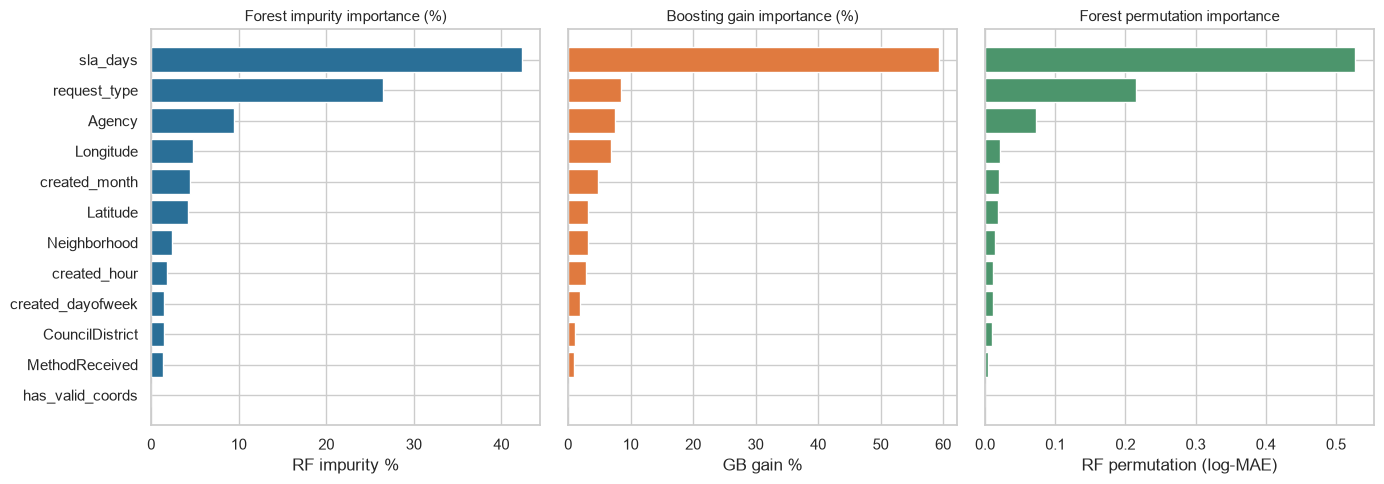

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
panels = [
    ("RF impurity %", "#2a6f97", "Forest impurity importance (%)"),
    ("GB gain %", "#e07a3f", "Boosting gain importance (%)"),
    ("RF permutation (log-MAE)", "#4c956c", "Forest permutation importance"),
]
for ax, (col, color, title) in zip(axes, panels):
    s = imp[col].sort_values()
    ax.barh(s.index, s.values, color=color)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel(col)
for ax in axes[1:]:
    ax.set_yticklabels([])
savefig("18_feature_importance")

The forest and the boosted model describe themselves completely differently, and the disagreement is
not an artifact — it is the same encoding mechanism section 8 identified, showing up a third time.

**The forest leans on the deadline; XGBoost leans on request type.** Permutation importance — the
measure that is actually held out and actually about prediction — puts `sla_days` first for the
forest by more than a factor of two over request type (0.53 against 0.22 log-days of MAE). XGBoost
credits request type with 59% of its gain and the deadline with 8.5%.

The cardinality caveat does not explain this away. We expected impurity importance to inflate
`sla_days`, which has 113,995 distinct values and therefore far more candidate split points than any
other column, and it does: 42% against request type's 26%. But permutation importance is not
vulnerable to that, and it agrees. The forest really does depend on the deadline most.

**The explanation is part 2's collinearity finding, read forwards.** Part 2 established that about
91% of the deadline's variation is request type — the deadline is largely a label for the kind of
work. For the forest, that makes `sla_days` a *numeric proxy for request type*, and a far more
usable one than request type itself: the forest sees request type only as arbitrary integer codes
that a split can merely cut, whereas the deadline encodes much of the same grouping on a real
number line that a single threshold can exploit. Shuffling `sla_days` destroys the forest's main
handle on what kind of request it is looking at. XGBoost, which partitions categorical levels
natively, has no need for the proxy and uses the column itself.

This is the same mechanism that made agency valuable to the forest and useless to XGBoost in section
8, and it is the clearest practical consequence of the encoding limitation flagged in section 3.
The forest reaches request type through two proxies — the deadline and agency — because it cannot
reach it directly. It also means the three importance columns should not be averaged or treated as
competing estimates of one quantity: they are answers to different questions about two models that
solved the same problem differently.

**Neighborhood is where the two models disagree most sharply.** XGBoost gives it 7.5% of gain,
fourth overall and ahead of agency; the forest's permutation importance puts it tenth, at 0.010.
That is section 8's finding from the other direction — XGBoost invests heavily in neighborhood
structure, and that investment is exactly what fails to carry into 2025.

## 10. SHAP

Importance says *how much* a column matters. SHAP says *which way* and *for which requests*: every
prediction is decomposed into one additive contribution per feature, on the log-days scale, and
those contributions sum exactly to the prediction minus the dataset average.

`TreeExplainer` is exact for tree ensembles, and it runs on the boosted model rather than the forest
because 300 deep trees are far more expensive to walk than ~100 shallow ones. The explanations below
therefore describe the gradient boosting model on set B, not the winning forest; the two agree on
the broad ordering.

SHAP on 4,000 test rows in 1s
Base value (average prediction): 1.620 log-days = 4.05 days

Share of total absolute SHAP contribution


,percent
request_type,58.1600
sla_days,17.7300
Neighborhood,7.9400
created_month,5.7700
created_dayofweek,3.1800
Agency,3.1400
created_hour,2.4500
MethodReceived,0.9500
Longitude,0.4200
CouncilDistrict,0.1800


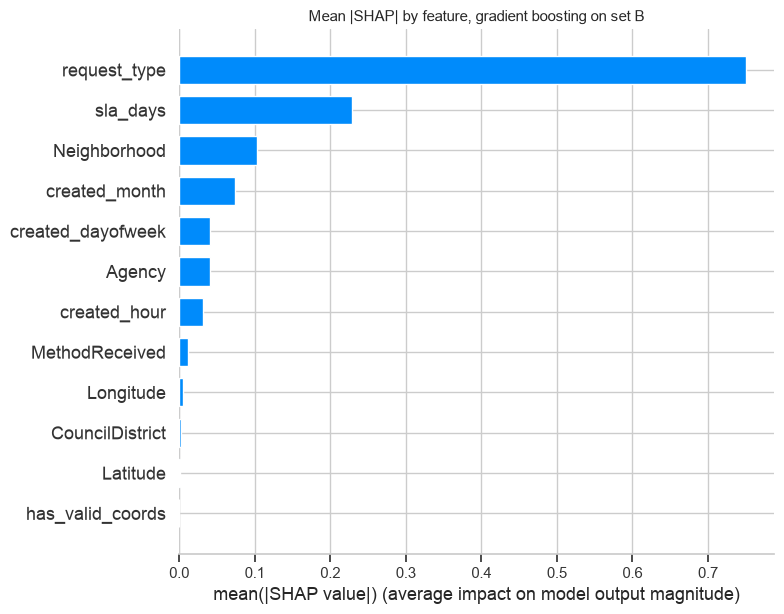

In [17]:
shap_n = 4_000
shap_idx = np.random.default_rng(SEED).choice(len(test), shap_n, replace=False)
X_shap = make_X(test, "B", "category").iloc[shap_idx]

t = time.time()
explainer = shap.TreeExplainer(xgb_models["B"])
shap_values = explainer.shap_values(X_shap)
base_value = float(np.ravel(explainer.expected_value)[0])
print(f"SHAP on {shap_n:,} test rows in {time.time() - t:.0f}s")
print(f"Base value (average prediction): {base_value:.3f} log-days "
      f"= {np.expm1(base_value):.2f} days")

contrib = pd.Series(np.abs(shap_values).mean(axis=0), index=X_shap.columns)
contrib = (contrib / contrib.sum() * 100).sort_values(ascending=False)
print("\nShare of total absolute SHAP contribution")
display(contrib.round(2).to_frame("percent"))

plt.figure()
shap.summary_plot(shap_values, X_shap, plot_type="bar", show=False, max_display=12)
plt.title("Mean |SHAP| by feature, gradient boosting on set B", fontsize=11)
savefig("19_shap_importance")

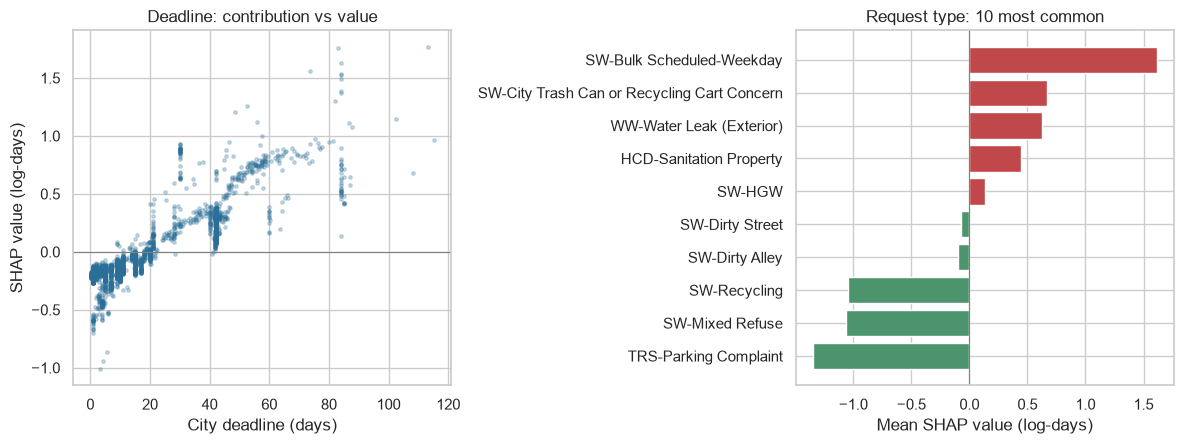

In [18]:
# Where does the deadline push a prediction? The one continuous feature worth a dependence plot.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
j = list(X_shap.columns).index("sla_days")
axes[0].scatter(X_shap["sla_days"], shap_values[:, j], s=6, alpha=0.25, color="#2a6f97")
axes[0].axhline(0, color="gray", linewidth=0.8)
axes[0].set_xlabel("City deadline (days)")
axes[0].set_ylabel("SHAP value (log-days)")
axes[0].set_title("Deadline: contribution vs value")

top_types = test["request_type"].value_counts().head(10).index
jt = list(X_shap.columns).index("request_type")
type_shap = (pd.DataFrame({"t": X_shap["request_type"].astype(str), "s": shap_values[:, jt]})
             .query("t in @top_types").groupby("t")["s"].mean().sort_values())
axes[1].barh(type_shap.index, type_shap.values,
             color=np.where(type_shap.values > 0, "#c1484a", "#4c956c"))
axes[1].axvline(0, color="gray", linewidth=0.8)
axes[1].set_xlabel("Mean SHAP value (log-days)")
axes[1].set_title("Request type: 10 most common")
savefig("20_shap_detail")

One caveat before reading these: this is the **set B** model, which is not our best one. Set A wins
on 2025. We explain set B because it is the only fitted model that contains the location columns,
and what it does with them is the question section 8 raised. Its request-type and deadline structure
matches set A's; its neighborhood contributions are the part that does not survive to 2025.

The base value is 1.62 log-days, or **4.05 days** — the average prediction, and the point every
decomposition starts from. Request type supplies 58% of all absolute contribution, the deadline 18%,
and neighborhood 7.9%; the ordering tracks XGBoost's gain importance, as it should, since both
describe the same model.

The deadline's dependence plot rises steadily (correlation 0.89 between the deadline and its own
contribution) and **crosses zero right around the three-week mark**. A deadline under 21 days
actively pushes a prediction *down* — by about 0.22 log-days for same-day deadlines — and a long
deadline pushes it up, reaching +0.77 past two months. This is part 2's positive within-type slope
seen per request instead of as one coefficient, and the vertical spread at any fixed deadline is the
interaction a single slope could not express: the same deadline means different things for different
kinds of work.

The request-type panel needs reading against the error analysis in section 11, because the two
together say something neither says alone. The three highest-volume types — parking complaints,
mixed refuse and recycling — all push predictions *down* by 1.0 to 1.3 log-days, while scheduled
bulk pickup pushes up by 1.62 (it is genuinely scheduled work, which is why part 2 found its 42-day
deadline closing faster than the 30-day one).

Parking complaints are the instructive case, and the strongest shift in the panel at −1.35. The
model pushes them firmly toward "fast", and for the typical parking complaint that is correct: the
median closes in **0.46 days**. Yet they are also the second-worst type in the error table, at 25.4
days of MAE with a bias of +25.4 across 46,179 requests. Both facts hold at once because the
distribution is bimodal — most close within hours, a minority runs for months — and a single-number
prediction trained on squared log error lands near the median and therefore misses the tail
completely. The SHAP panel shows the model making a defensible choice; the error table shows what
that choice costs.

## 11. Where the model goes wrong

The research question asks whether performance differs across neighborhoods and request types, so
the error breakdown is a result in its own right, not a diagnostic afterthought. Both tables use the
best model by test MAE.

`bias` is mean actual minus mean predicted, in days. Positive means the model is **optimistic**:
those requests took longer than it said.

In [19]:
fitted = results[results.apply(lambda r: (r["model"], r["features"]) in preds, axis=1)]
best_row = fitted.loc[fitted["MAE"].idxmin()]
best_key = (best_row["model"], best_row["features"])
best_name = f"{best_row['model']} (set {best_row['features']})"
best_pred_log = preds[best_key]
best_pred_days = np.expm1(best_pred_log)
print(f"Best model: {best_name}, test MAE {best_row['MAE']:.3f} days")

err = pd.DataFrame({
    "request_type": test["request_type"].astype(str).to_numpy(),
    "Neighborhood": test["Neighborhood"].astype(str).to_numpy(),
    "actual": d["test"],
    "pred": best_pred_days,
})
err["abs_err"] = (err["actual"] - err["pred"]).abs()
err["signed"] = err["actual"] - err["pred"]

by_type = (err.groupby("request_type")
           .agg(n=("abs_err", "size"), MAE=("abs_err", "mean"),
                bias=("signed", "mean"), median_actual=("actual", "median"))
           .query("n >= 2000").sort_values("MAE", ascending=False))
print("\nHardest request types (at least 2,000 test requests)")
display(by_type.head(10).round(2))
print("Easiest request types")
display(by_type.tail(5).round(2))

by_hood = (err.groupby("Neighborhood")
           .agg(n=("abs_err", "size"), MAE=("abs_err", "mean"), bias=("signed", "mean"))
           .query("n >= 2000").sort_values("MAE", ascending=False))
print(f"\nNeighborhood MAE, {len(by_hood)} neighborhoods with at least 2,000 test requests")
display(pd.concat([by_hood.head(5), by_hood.tail(5)]).round(2))
by_type.to_csv(RESULTS_DIR / "error_by_request_type.csv")
by_hood.to_csv(RESULTS_DIR / "error_by_neighborhood.csv")

Best model: Gradient boosting (set A), test MAE 10.409 days

Hardest request types (at least 2,000 test requests)


,n,MAE,bias,median_actual
request_type,,,,
TRT-Sign Damaged/Sign Structure,2691,72.4500,69.3900,34.1200
TRS-Parking Complaint,46179,25.4300,25.3700,0.4600
Other,8354,25.1200,17.9100,4.2600
FOR-Down Tree,2051,22.8700,6.3700,2.8500
WW-Water Leak (Exterior),11986,22.8200,16.4300,3.1600
ECC-Citizen Complaint or Concern,2329,17.7800,15.3100,3.7700
SW-City Trash Can or Recycling Cart Concern,14765,16.1200,12.3000,14.0800
TRS-48 Hour Parking/Abandoned Vehicle,9189,14.5700,11.6000,12.7700
BGE-StLight(s) Out,8431,14.1600,10.5800,1.2200


Easiest request types


,n,MAE,bias,median_actual
request_type,,,,
SW-Recycling,17075,0.7200,0.6100,0.8400
TRM-Snow/Icy Conditions,2829,0.6700,-0.0700,0.5800
HLTH-Animal In Danger/Injured/Abused/Neglected,5865,0.3600,0.0600,0.0800
SW-Public (Corner) Trash Can Issue,2236,0.2700,0.1300,0.7100
TRM-Pickup Pothole,5277,0.0100,-0.0000,0.0000



Neighborhood MAE, 73 neighborhoods with at least 2,000 test requests


,n,MAE,bias
Neighborhood,,,
Washington Village/Pigtown,5761,15.6900,13.3700
Riverside,3676,15.0000,12.0600
CARE,2124,13.7600,10.8800
Unknown,12429,13.6700,8.0200
Mount Clare,3143,13.0700,5.8900
Edgewood,2044,7.3100,4.2800
Berea,3477,7.2100,3.7200
Park Circle,2670,7.0500,4.2500
Upper Fells Point,3739,6.7200,4.2800


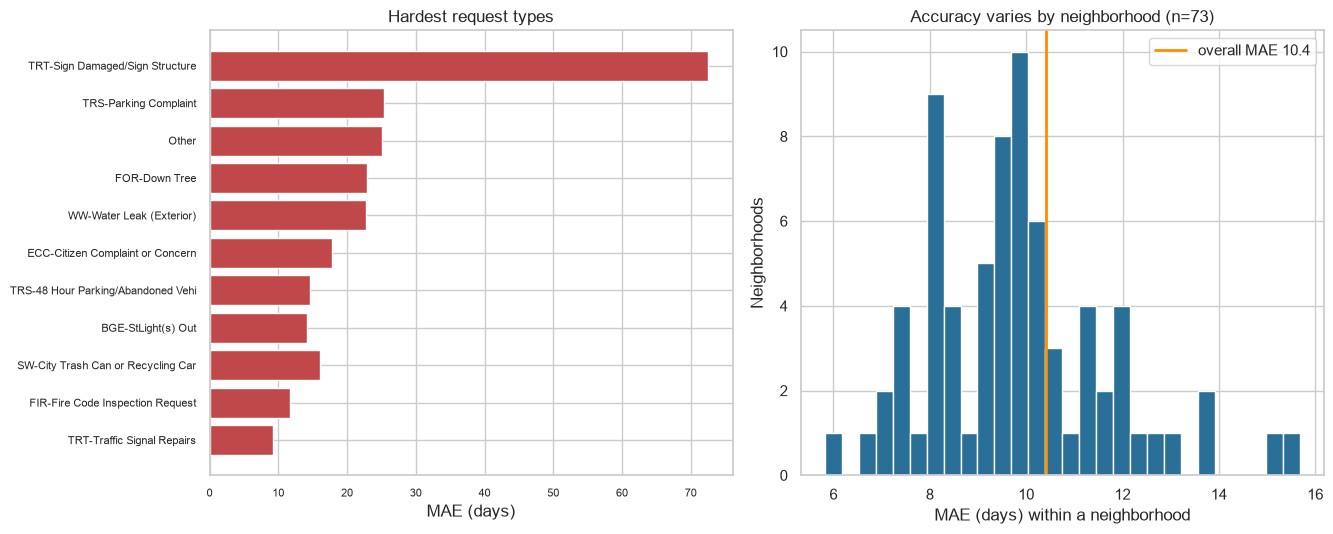

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5))

top = by_type.head(12).iloc[::-1]
axes[0].barh(top.index.str.slice(0, 34), top["MAE"], color="#c1484a")
axes[0].set_xlabel("MAE (days)")
axes[0].set_title("Hardest request types")
axes[0].tick_params(labelsize=8)

axes[1].hist(by_hood["MAE"], bins=28, color="#2a6f97", edgecolor="white")
axes[1].axvline(best_row["MAE"], color="darkorange", linewidth=2,
                label=f"overall MAE {best_row['MAE']:.1f}")
axes[1].set_xlabel("MAE (days) within a neighborhood")
axes[1].set_ylabel("Neighborhoods")
axes[1].set_title(f"Accuracy varies by neighborhood (n={len(by_hood)})")
axes[1].legend()
savefig("21_error_breakdown")

The overall MAE of 10.4 days is an average over wildly unequal cases, and the inequality is the
result.

**Error is concentrated in a few request types, and the model is optimistic in almost all of them.**
Damaged-sign work is off by 72 days on average with a bias of +69: the model predicts a few days and
the median case actually takes 34. Parking complaints, at 46,179 test requests, are off by 25 days.
At the other end, pothole pickup has an MAE of **0.01 days** — the model is essentially exact
because those requests close the moment they are filed. That is not skill. It is the
administrative-closure problem the cleaning notebook flagged as an open question in its "next
steps", visible now as a request type with zero resolution time, and it means some share of our
headline accuracy comes from predicting a clerical act rather than any city work.

**Bias is positive nearly everywhere.** Almost every hard type took longer than predicted, and no
type is badly pessimistic. A model trained on squared error in log space predicts something near the
conditional median, so it systematically under-calls the long right tail. That is a property of the
target and the loss, not a bug, but it does mean the model should not be described as estimating how
long a request will take. It estimates how long a *typical* request of that kind takes.

**Accuracy differs by nearly a factor of three across neighborhoods.** Among the 73 neighborhoods
with at least 2,000 test requests, MAE runs from 5.8 days in Poppleton to 15.7 in Washington
Village/Pigtown, and **the bias is positive in all 73** — there is not one neighborhood where the
model is, on average, pessimistic. This is a direct answer to the second half of the research
question: prediction performance is *not* uniform across the city.

It is not yet an equity finding, though, and we should be careful not to present it as one. The
spread could reflect the mix of request types each neighborhood files rather than anything about the
neighborhood itself, since request type drives both the prediction and the error. Separating those
two explanations needs the error decomposed within request type, which is a specific and tractable
task for the final phase. One practical note: `Unknown` is the fourth-worst "neighborhood" with
12,429 test requests, and that is an address-matching artifact, not a place.

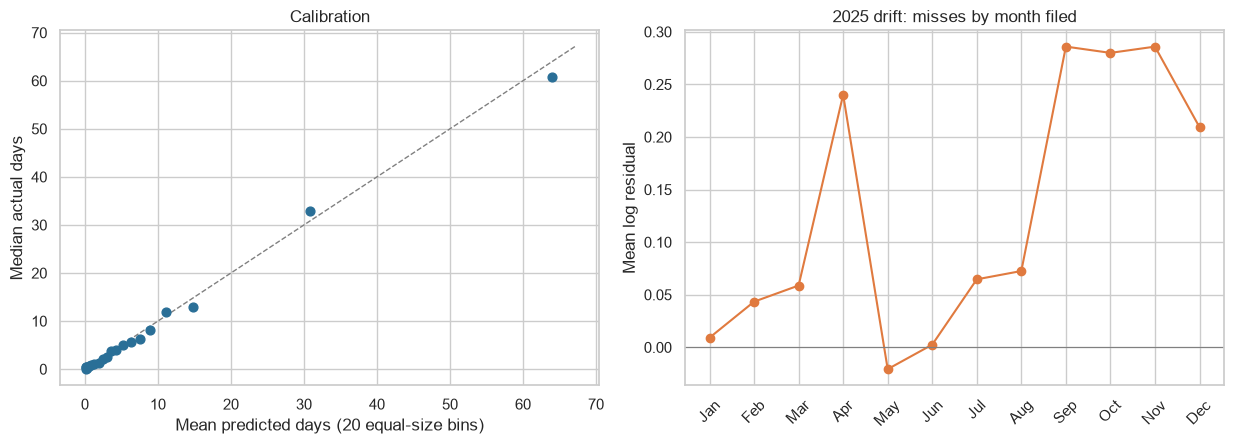

Mean log residual by 2025 month (positive = took longer than predicted)


month,1,2,3,4,5,6,7,8,9,10,11,12
mean_log_residual,0.0090,0.0430,0.0590,0.2400,-0.0210,0.0030,0.0650,0.0730,0.2860,0.2800,0.2860,0.2090


In [21]:
# Calibration: does the model track actual time across its own prediction range?
q = pd.qcut(err["pred"], 20, duplicates="drop")
cal = err.groupby(q, observed=True).agg(pred=("pred", "mean"), actual=("actual", "median"),
                                        n=("actual", "size"))
month_err = (pd.DataFrame({"month": test["month_num"].to_numpy(),
                           "resid_log": y["test"] - best_pred_log})
             .groupby("month")["resid_log"].mean())

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
lim = cal[["pred", "actual"]].to_numpy().max() * 1.05
axes[0].plot([0, lim], [0, lim], color="gray", linestyle="--", linewidth=1)
axes[0].scatter(cal["pred"], cal["actual"], s=40, color="#2a6f97", zorder=3)
axes[0].set_xlabel("Mean predicted days (20 equal-size bins)")
axes[0].set_ylabel("Median actual days")
axes[0].set_title("Calibration")

axes[1].plot(month_err.index, month_err.values, marker="o", color="#e07a3f")
axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].set_xticks(range(1, 13), MONTH_NAMES, rotation=45)
axes[1].set_ylabel("Mean log residual")
axes[1].set_title("2025 drift: misses by month filed")
savefig("22_calibration_and_drift")

print("Mean log residual by 2025 month (positive = took longer than predicted)")
display(month_err.round(3).to_frame("mean_log_residual").T)

## 12. Where this leaves the project

**What worked.** Both tree models beat part 2's linear regression on the 2025 test year.
**XGBoost on set A is the best model at 10.41 days** of MAE, with the random forest on set B just
behind at 10.49, against 11.59 for the linear regression and 11.92 for predicting each request
type's median. The improvement is about 1.5 days per request over that median rule, and it is the
project's first clear win over it — part 2's linear model managed 0.33.

**The most useful thing we learned is that "which features help" has no answer independent of the
model.** We built set B expecting location to be the payoff, since that is what part 2 had to leave
out. Instead the same seven columns are worth −0.35 days to the forest and +0.42 to XGBoost, and
almost every individual column that helps one hurts the other. Agency is the sharpest case: the
forest's best single addition (−0.32) and XGBoost's second worst (+0.12).

**One mechanism explains all of it: how each model reads a categorical.** The forest sees request
type as arbitrary integer codes it can only cut, so it cannot represent that grouping directly and
reaches for proxies — agency, and above all the city deadline, which permutation importance ranks
as its single most-used feature even though it is 91% determined by request type. XGBoost partitions
categorical levels natively, so it extracts request type directly, has no use for proxies, and
instead over-carves the 280-level neighborhood column into 2024-specific structure. The blunt
encoding generalized better than the sharp one, not because it was better but because it could not
represent what failed to transfer.

**What did not work.** Optimizing MAE directly was the clearest failure: `reg:absoluteerror` scored
11.16 against 10.83 for the identical feature set, despite the reasoning in 6.1 that it should match
our headline metric better. Set B hurt XGBoost badly, with neighborhood alone costing 0.60 days.
Restricting the categorical splits did fix most of that (10.83 → 10.47), so the overfitting
diagnosis was correct — but our validation scheme ranked that winning configuration **last**.

**The methodological finding we did not expect, and the one worth presenting.** Our validation
design is broken, and the notebook caught it three separate times. It got the set A versus set B
comparison **backwards in sign** for XGBoost (validation said B was better by 0.17; the test year
said A was better by 0.42). It ranked the categorical-regularization settings almost exactly
inversely to the test year, putting the best configuration last. And the forest setting it chose
for set A scored worse on 2025 than the setting it chose for set B. A validation set drawn from
inside the training year measures generalization *across months*, while the test set measures
generalization *across years*, and in this data those are different problems. Every hyperparameter
in this notebook was tuned against the wrong target, which makes this the first thing to fix.

**The obstacle that is still unsolved.** Every model is optimistic in the second half of 2025: mean
log residuals run +0.28 to +0.29 for September through November, against roughly zero in the first
half, and the bias is positive in all 73 neighborhoods we can measure. Part 2 found this, no model
class fixes it, and it is the same phenomenon that breaks the validation design — a change in the
city's behavior over time rather than a shortcoming of any fit. This is the clearest target for the
final phase.

**Plan for the final project.**

1. **Fix the validation design first**, because every other comparison depends on it. Use a rolling
   origin: tune on 2024 and validate on early 2025, or fit on successive windows and validate on the
   window that follows. Hyperparameter choice then faces the drift the test year actually contains.
   This is cheap, and section 8 shows the current scheme is actively misleading.
2. **Attack the drift directly.** Add features describing conditions at filing time rather than the
   calendar: the agency's open-request backlog, the recent median resolution time for that request
   type, days since the start of the series. A model that knows the system was already slow in
   October 2025 does not need to have seen October 2025.
3. **Settle the administrative-closure question.** Pothole pickup has an MAE of zero because those
   requests close on creation. The cleaning notebook raised this and it is still open. Until it is
   decided, part of our reported accuracy is predicting data entry rather than city work.
4. **Decompose the neighborhood error within request type.** The four-fold spread in accuracy across
   neighborhoods is currently confounded with which request types each neighborhood files. Separating
   those is what turns a measurement into the equity finding the research question asks for.
5. **Enrich with Census ACS data** joined on neighborhood, which replaces 280 opaque levels with
   interpretable quantities — and, given that fine-grained neighborhood identity is exactly what
   failed to transfer to 2025, may generalize where the raw column did not.
6. **Model the tail instead of ignoring it.** Every model under-calls slow requests because it
   targets the conditional median. Quantile regression, or predicting whether a request will exceed
   its deadline at all, would be more useful than a point estimate and would address the bias that
   runs through the whole error analysis.